# Conley–Morse graph of the Leslie map

$$f(x_0, x_1) = \big((\theta_1 x_0 + \theta_2 x_1)\, e^{-0.1 (x_0 + x_1)},\ 0.7\, x_0\big)$$

The notebook covers phase space with a grid of boxes and computes a rigorous image of every box using interval arithmetic. CMGDB then finds the Morse sets, the Morse graph, and the Conley index of each Morse set.

The parameters $\theta_1, \theta_2$ can be single values or intervals. With intervals, the result holds for every parameter value in the interval.

The notebook runs four computations, each in its own section with its own parameters, so **Run all** produces all four in order.

In [1]:
!pip install -q CMGDB python-flint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 705.7/705.7 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 66.7 MB/s eta 0:00:00


In [2]:
import CMGDB
import math, time
import matplotlib
from flint import arb
import graphviz, re, itertools
import matplotlib.pyplot as plt

# show figures in the notebook at twice the resolution
# resolution of PDFs is good either way
%config InlineBackend.figure_format = 'retina'


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [24]:
import sys
# If your folder name has spaces, type it exactly as it appears in Drive
sys.path.insert(0, '/content/drive/MyDrive/AMS Colabs')

import cmgdb_retract

## Settings

These apply to all four computations. Each computation sets its own `theta1`, `theta2` and `subdiv`.

* `lower_bounds`, `upper_bounds`: the region of phase space to study.
* `subdiv_max`: Morse sets are refined up to this level to check whether they are real. Sets that disappear under refinement are removed as spurious.
* `inflation`: how many times larger each box is drawn in the inflated Morse-set plots. 1 means actual size.
* `graph_corner`, `graph_width`: where the Morse graph is drawn on the Morse-set plots (`'upper right'` or `'upper left'`) and how wide it is, as a fraction of the plot.

In each computation:
* `theta1`, `theta2`: each is `(lower, upper)`. For a single value, use the same number twice. Write the numbers as strings, such as `"23.3"`, so they are read as exact decimals.
* `subdiv`: the grid has $2^{\text{subdiv}}$ boxes. 25 subdivisions results in about 34 million boxes and takes about 10 minutes; each step down is about twice as fast.

In [5]:
lower_bounds = [-0.001, -0.001]
upper_bounds = [90.0, 70.0]

subdiv_max = 32

# Morse sets are also drawn with every box enlarged this many times about its center,
# so small sets are easier to see (1 = actual size). See the note under Results.
inflation = 10

# Where the Morse graph is drawn on the Morse-set plots, and its width as a fraction of the plot
graph_corner = 'upper right'      # or 'upper left'
graph_width = 0.60                # larger graph -> larger labels (about 12.5 pt)


## The map

`f` is written exactly like the formula, but with interval inputs. To study a different map, edit `f`.

`F(rect)` is what CMGDB calls: it turns a box `[x0_min, x1_min, x0_max, x1_max]` into intervals, applies `f`, and returns a box that contains the image. The ends are rounded outward so that the box always contains the true image.

`th1` and `th2` are set in each computation from that computation's `theta1` and `theta2`.

In [6]:
def interval(lo, hi):
    return arb(lo).union(arb(hi))

def f(x0, x1):
     return [(th1 * x0 + th2 * x1) * (-(x0 + x1) * arb("0.1")).exp(),
             arb("0.7") * x0]


def F(rect):
    x0 = interval(rect[0], rect[2])
    x1 = interval(rect[1], rect[3])
    y0, y1 = f(x0, x1)
    # round outward so the box still contains the image after converting to float
    # should not be necessary with FLINT's default precision
    down = lambda v: math.nextafter(float(v.lower()), -math.inf)
    up = lambda v: math.nextafter(float(v.upper()), math.inf)
    return [down(y0), down(y1), up(y0), up(y1)]


## Results

Each node is labelled `n : (CH0, CH1, CH2)`, the Conley index in dimensions 0, 1, and 2 in homology. Each entry is the characteristic polynomial of the index map; `0` means trivial. For example:
* `(x^3-1, 0, 0)`: is the index of an attracting period-3 orbit
* `(0, x^3-1, 0)`: is the index of a period-3 saddle
* `(x-1, x-1, 0)`: is the index of an attracting invariant circle
* `(0, 0, x-1)`: is the index of a 2d repelling fixed point

Note that a nontrivial index implies that the maximal invariant set inside the region is nonempty, but the converse does not hold. A region with a trivial Conley index can contain an nonempty invariant set.

The box at the origin shows a trivial index only because it sits on the edge of the region. Setting `lower_bounds = [-1, -1]` shows the saddle there.

**Colors.** Each computation sets `clist`, the color of Morse set 0, 1, 2, … in order. The colors are the exact colors of the published figures.

**Actual and inflated plots.** Each computation draws its Morse sets twice. The first plot shows every box at its true size. The second enlarges every box by the factor `inflation` about its own center, so sets only a few boxes wide can be seen. Positions are unchanged, but the drawn sets are thicker than the true sets. Small sets are drawn last so they stay on top.

Both plots also show the Morse graph in a corner, as in the published figures. It is drawn with matplotlib, so it stays sharp at any size and in PDF files: pass a file name, e.g. `plot_sets(morse_graph, clist, fname='figure.pdf')`, to save a figure.

In [7]:
# CMGDB's Morse graph, with white labels written as in the paper: z instead of x, exponents raised, and a proper minus sign
def plot_graph(morse_graph, clist):
    source = CMGDB.PlotMorseGraph(morse_graph, clist=clist).source
    def typeset(match):
        label = match.group(1).replace('-', ' &minus; ').replace('+', ' + ').replace('x', '<I>z</I>')
        label = re.sub(r'\^(\d+)', r'<SUP><FONT POINT-SIZE="9">\1</FONT></SUP>', label)
        return f'label=<{label}>'
    source = re.sub(r'label="([^"]*)"', typeset, source)
    return graphviz.Source(source.replace('style=filled', 'style=filled, fontcolor=white'))


# The Morse graph drawn with matplotlib on axes `g`, so it stays sharp at any size and in PDF.
def graph_rows(morse_graph):
    """Row of each node: sources in row 0, each node below all its parents, attractors last."""
    N = morse_graph.num_vertices()
    kids = [list(morse_graph.adjacencies(v)) for v in range(N)]
    parents = [[u for u in range(N) if v in kids[u]] for v in range(N)]
    row = {}
    def find_row(v):
        if v not in row:
            row[v] = 1 + max((find_row(u) for u in parents[v]), default=-1)
        return row[v]
    for v in range(N): find_row(v)
    bottom = max(row.values())
    for v in range(N):
        if not kids[v]: row[v] = bottom
    return row, kids, parents


def draw_graph(g, morse_graph, clist, fontsize=13):
    N = morse_graph.num_vertices()
    row, kids, parents = graph_rows(morse_graph)
    bottom = max(row.values())
    # columns: each node goes under its parents, nodes in a row keep their order
    col = {}
    for r in range(bottom + 1):
        nodes = [v for v in range(N) if row[v] == r]
        want = {v: (sum(col[u] for u in parents[v]) / len(parents[v]) if parents[v] else i)
                for i, v in enumerate(nodes)}
        nodes.sort(key=lambda v: (want[v], v))
        if len(nodes) == 1:
            col[nodes[0]] = want[nodes[0]]
            continue
        lo = int(min(want.values())) - len(nodes); hi = int(max(want.values())) + len(nodes) + 1
        best = min(itertools.combinations(range(lo, hi), len(nodes)),
                   key=lambda s: sum(abs(x - want[v]) for x, v in zip(s, nodes)))
        for x, v in zip(best, nodes): col[v] = x
    xs = list(col.values())
    g.set_xlim(min(xs) - 0.5, max(xs) + 0.5); g.set_ylim(-0.5, max(bottom, 1) + 0.5)
    g.set_axis_off()
    # labels: 0 : (z^3 - 1, 0, 0) in the STIX math font
    def label(v):
        parts = [re.sub(r'\^(\d+)', r'^{\1}', p.replace('x', 'z')) for p in morse_graph.annotations(v)]
        return rf'${v}\ :\ (' + r',\ '.join(parts) + ')$'
    nodes = {v: g.text(col[v], bottom - row[v], label(v), ha='center', va='center', color='white',
                       fontsize=fontsize, math_fontfamily='stix', zorder=3,
                       bbox=dict(boxstyle='ellipse,pad=0.25', fc=clist[v], ec='none'))
             for v in range(N)}
    # shrink the labels if neighboring ellipses would touch, then measure every ellipse
    def half_sizes():
        g.figure.canvas.draw()
        inv = g.transData.inverted(); out = {}
        for v, t in nodes.items():
            e = t.get_bbox_patch().get_window_extent()
            (x0, y0), (x1, y1) = inv.transform([(e.x0, e.y0), (e.x1, e.y1)])
            out[v] = ((x1 - x0) / 2, (y1 - y0) / 2)
        return out
    half = half_sizes()
    widest = 2 * max(a for a, b in half.values())
    if widest > 0.96:
        for t in nodes.values(): t.set_fontsize(fontsize * 0.96 / widest)
        half = half_sizes()
    # arrows from ellipse edge to ellipse edge
    for u in range(N):
        for v in kids[u]:
            (xu, yu), (xv, yv) = (col[u], bottom - row[u]), (col[v], bottom - row[v])
            dx, dy = xv - xu, yv - yu
            tu = 1 / ((dx / half[u][0]) ** 2 + (dy / half[u][1]) ** 2) ** 0.5
            tv = 1 / ((dx / half[v][0]) ** 2 + (dy / half[v][1]) ** 2) ** 0.5
            g.annotate('', xy=(xv - tv * dx, yv - tv * dy), xytext=(xu + tu * dx, yu + tu * dy),
                       arrowprops=dict(arrowstyle='-|>', color='black', lw=0.8,
                                       shrinkA=0, shrinkB=0, mutation_scale=12))


# Morse sets with the Morse graph in a corner, as in the published figures.
# inflation enlarges every box that many times about its center (1 = actual size).
def plot_sets(morse_graph, clist, inflation=1, fname=None):
    N = morse_graph.num_vertices()
    largest_first = sorted(range(N), key=lambda v: -len(morse_graph.morse_set(v)))
    pad = [0.035 * (u - l) for l, u in zip(lower_bounds, upper_bounds)]
    fig, ax = CMGDB.PlotMorseSets(morse_graph, clist=clist, morse_nodes=largest_first,
                                  scale_factor=[inflation] * N, fig_w=8, fig_h=6,
                                  xlim=(lower_bounds[0] - pad[0], upper_bounds[0]),
                                  ylim=(lower_bounds[1] - pad[1], upper_bounds[1]),
                                  axis_labels=False, rasterize=True, show=False)
    ax.set_aspect('auto')
    #ax.set_title("Actual size" if inflation == 1 else
    #             f"Boxes inflated {inflation}x for visibility (not actual size)")
    height = min(0.62, 0.17 * (1 + max(graph_rows(morse_graph)[0].values())))
    left = 1 - graph_width - 0.01 if graph_corner == 'upper right' else 0.01
    draw_graph(ax.inset_axes([left, 0.99 - height, graph_width, height]), morse_graph, clist)
    # Morse sets are stored as one 600-dpi image (they can have 10^5+ boxes); the text,
    # axes and Morse graph stay vector, so PDFs are small, fast in LaTeX, and sharp
    if fname:
        fig.savefig(fname, bbox_inches='tight', dpi=600)
    return fig, ax


## Computation 1: $\theta_1 = \theta_2 = 23.15$, 23 subdivisions.


In [8]:
theta1 = ("23.15", "23.15")
theta2 = ("23.15", "23.15")
subdiv = 23

th1 = interval(*theta1)
th2 = interval(*theta2)

start = time.time()
model = CMGDB.Model(subdiv, subdiv_max, subdiv, 10000, lower_bounds, upper_bounds, F)
morse_graph, map_graph = CMGDB.ComputeConleyMorseGraph(model)
print(f"Found {morse_graph.num_vertices()} Morse sets in {time.time() - start:.0f} seconds")

clist = ['#0000ff', '#f47a00', '#9f003c', '#000000', '#007191']


Found 5 Morse sets in 161 seconds


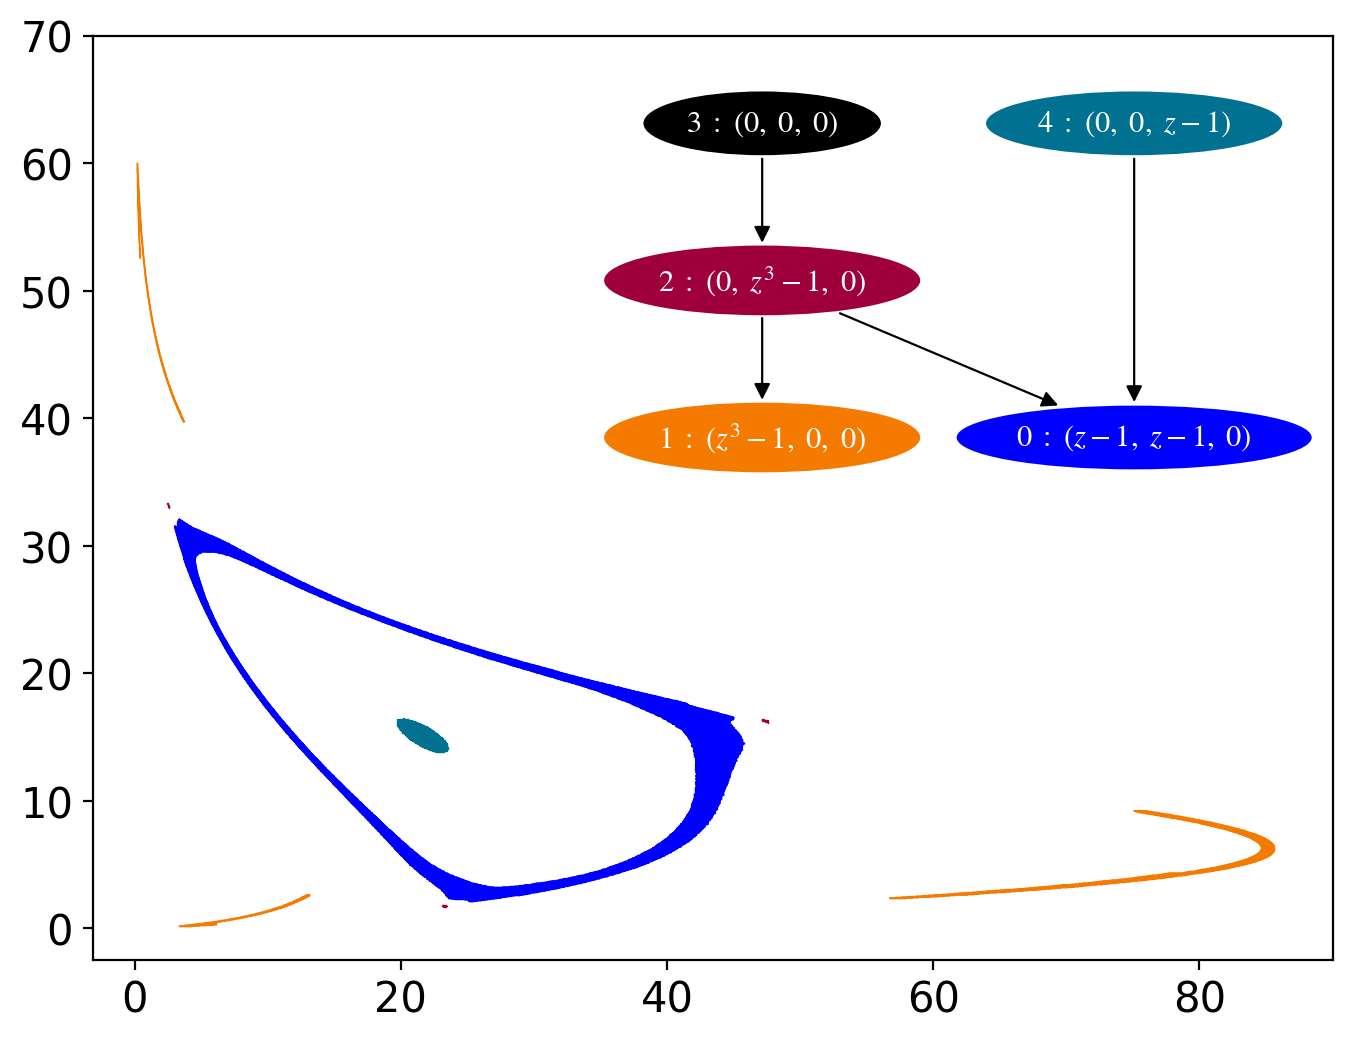

In [9]:
plot_sets(morse_graph, clist);

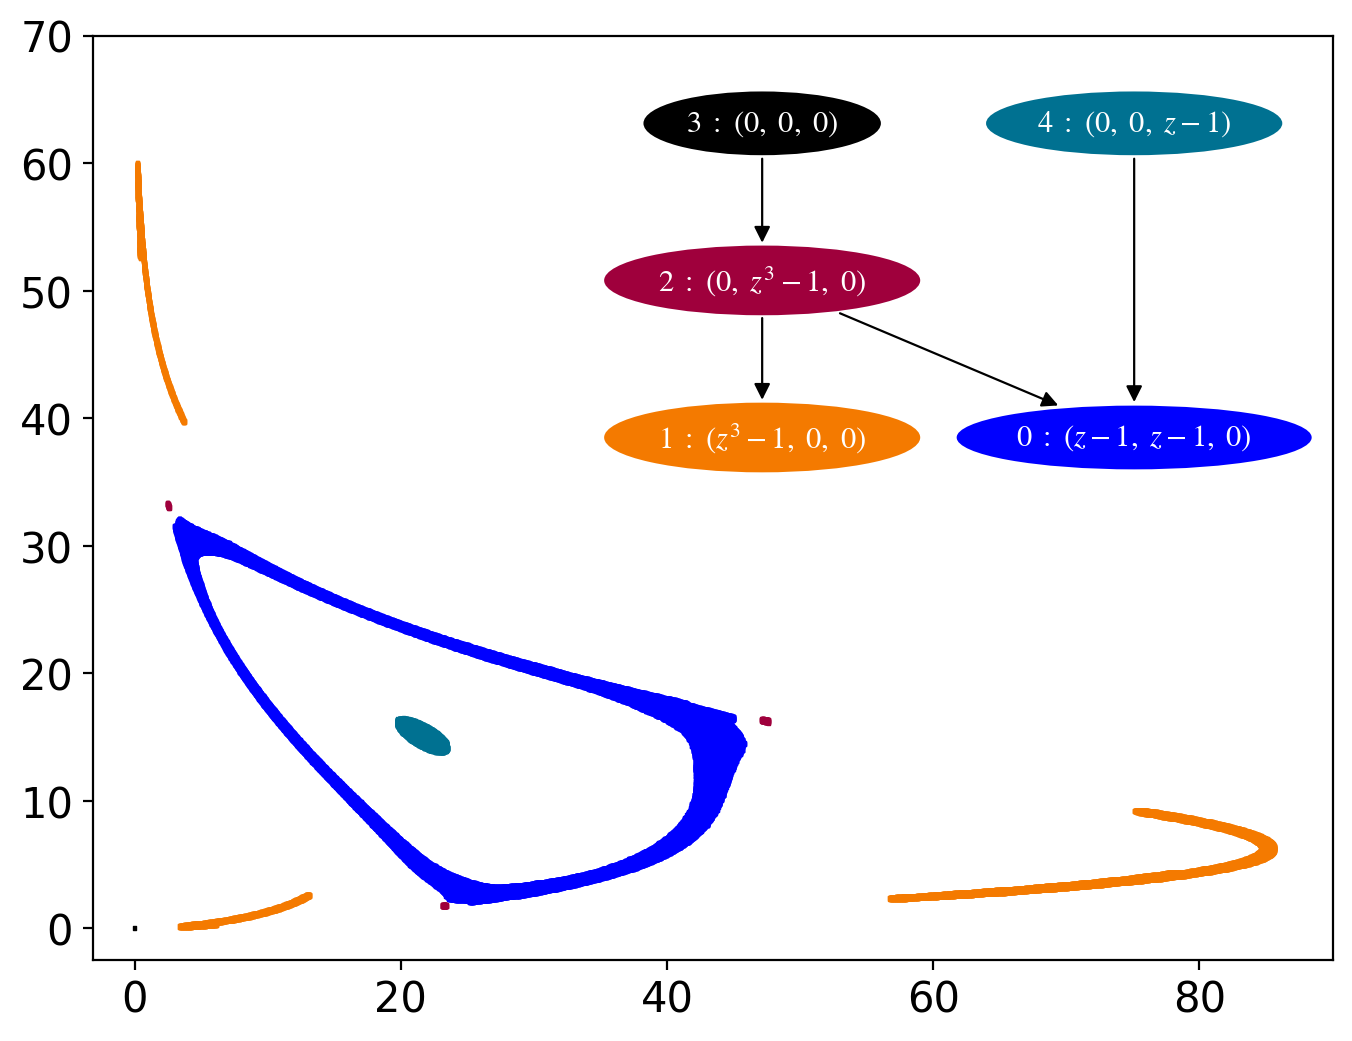

In [10]:
plot_sets(morse_graph, clist, inflation, fname='/content/drive/MyDrive/AMS Colabs/23p15_r23.pdf');

## Computation 2: $\theta_1 = \theta_2 = 23.15$, 25 subdivisions

Colors match `23p3_r25_final.pdf`.

In [11]:
theta1 = ("23.15", "23.15")
theta2 = ("23.15", "23.15")
subdiv = 25

th1 = interval(*theta1)
th2 = interval(*theta2)

start = time.time()
model = CMGDB.Model(subdiv, subdiv_max, subdiv, 10000, lower_bounds, upper_bounds, F)
morse_graph, map_graph = CMGDB.ComputeConleyMorseGraph(model)
print(f"Found {morse_graph.num_vertices()} Morse sets in {time.time() - start:.0f} seconds")

clist = ['#f47a00', '#008200', '#0000ff', '#9f003c', '#000000', '#007191']


Found 6 Morse sets in 561 seconds


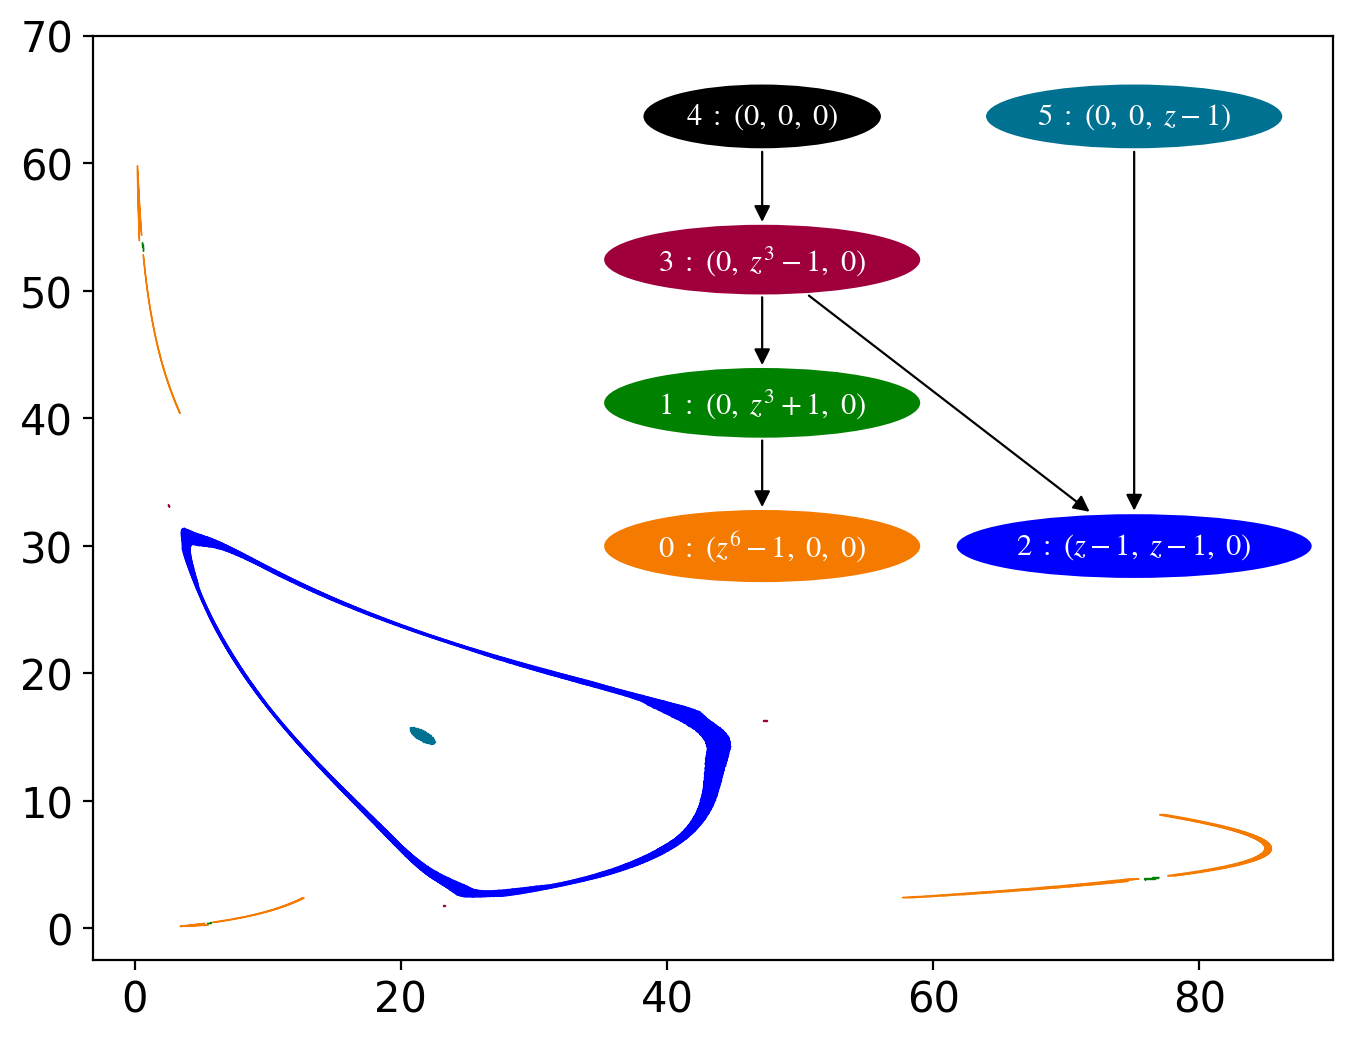

In [12]:
plot_sets(morse_graph, clist);

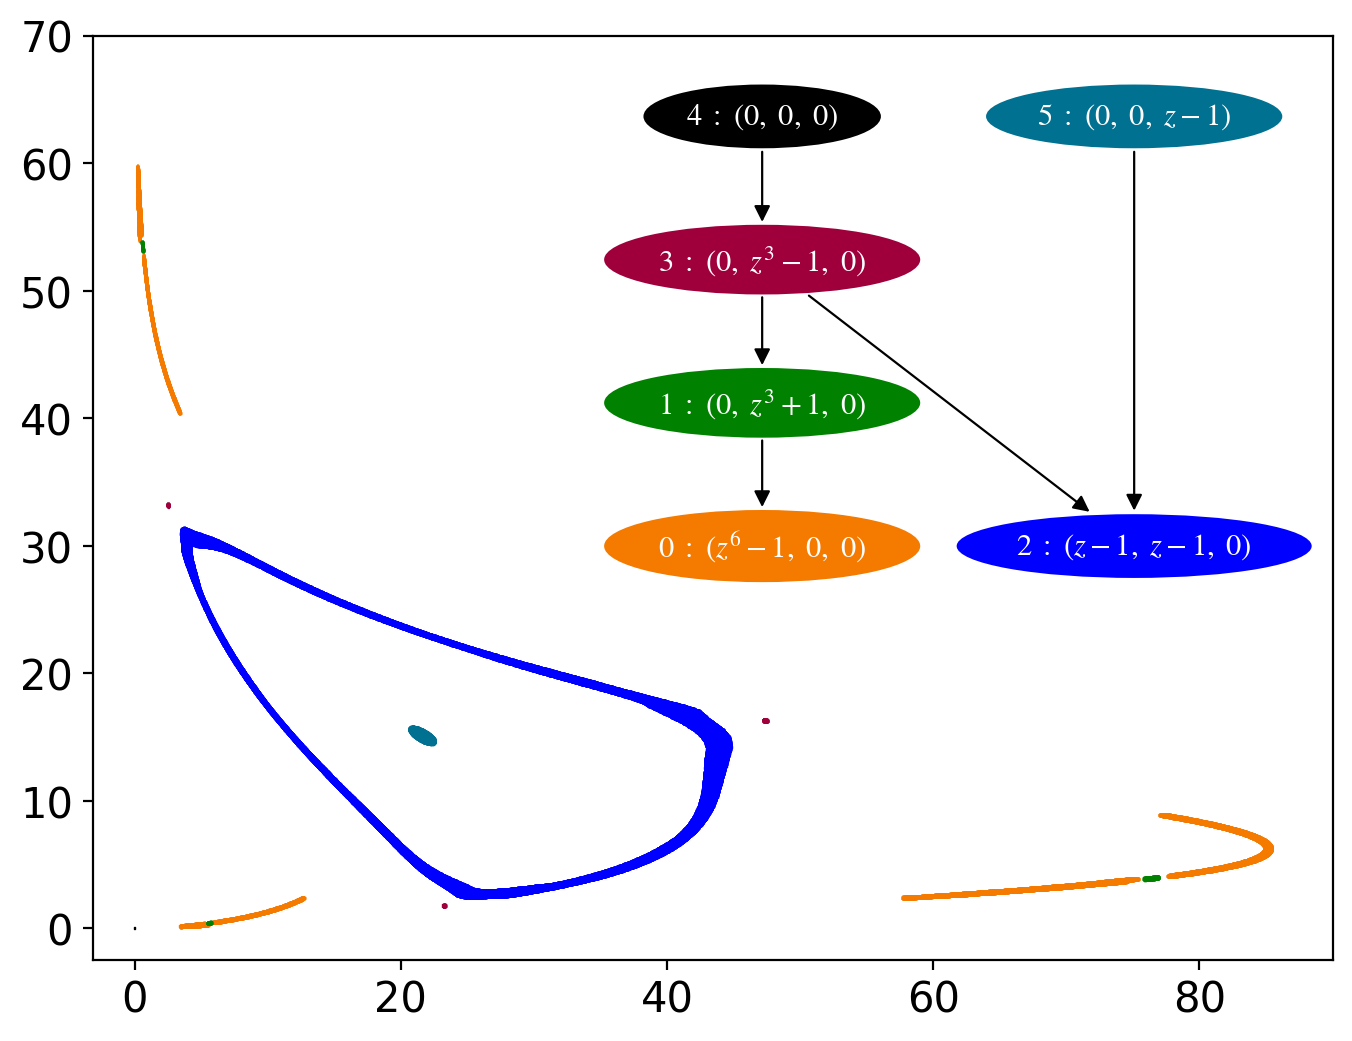

In [13]:
plot_sets(morse_graph, clist, inflation, fname='/content/drive/MyDrive/AMS Colabs/23p15_r25.pdf');

## Computation 3: $\theta_1 = \theta_2 = 23.45$, 23 subdivisions.

In [14]:
theta1 = ("23.45", "23.45")
theta2 = ("23.45", "23.45")
subdiv = 23

th1 = interval(*theta1)
th2 = interval(*theta2)

start = time.time()
model = CMGDB.Model(subdiv, subdiv_max, subdiv, 10000, lower_bounds, upper_bounds, F)
morse_graph, map_graph = CMGDB.ComputeConleyMorseGraph(model)
print(f"Found {morse_graph.num_vertices()} Morse sets in {time.time() - start:.0f} seconds")

clist = ['#f47a00', '#5400b4', '#000000', '#007191']


Found 4 Morse sets in 150 seconds


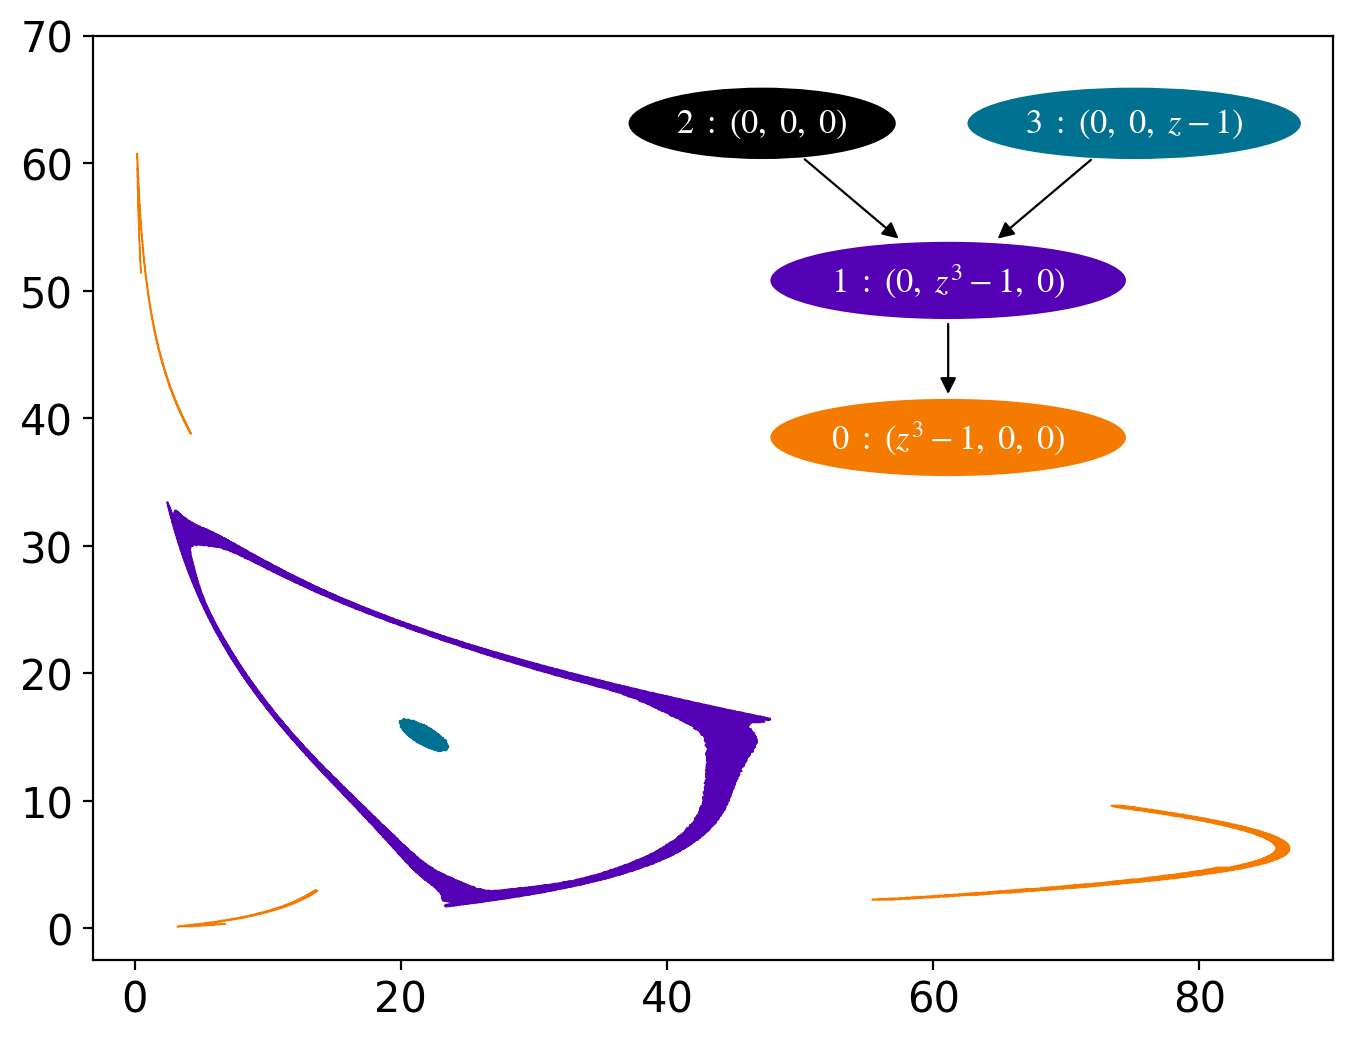

In [15]:
plot_sets(morse_graph, clist);

(<Figure size 800x600 with 1 Axes>, <Axes: >)

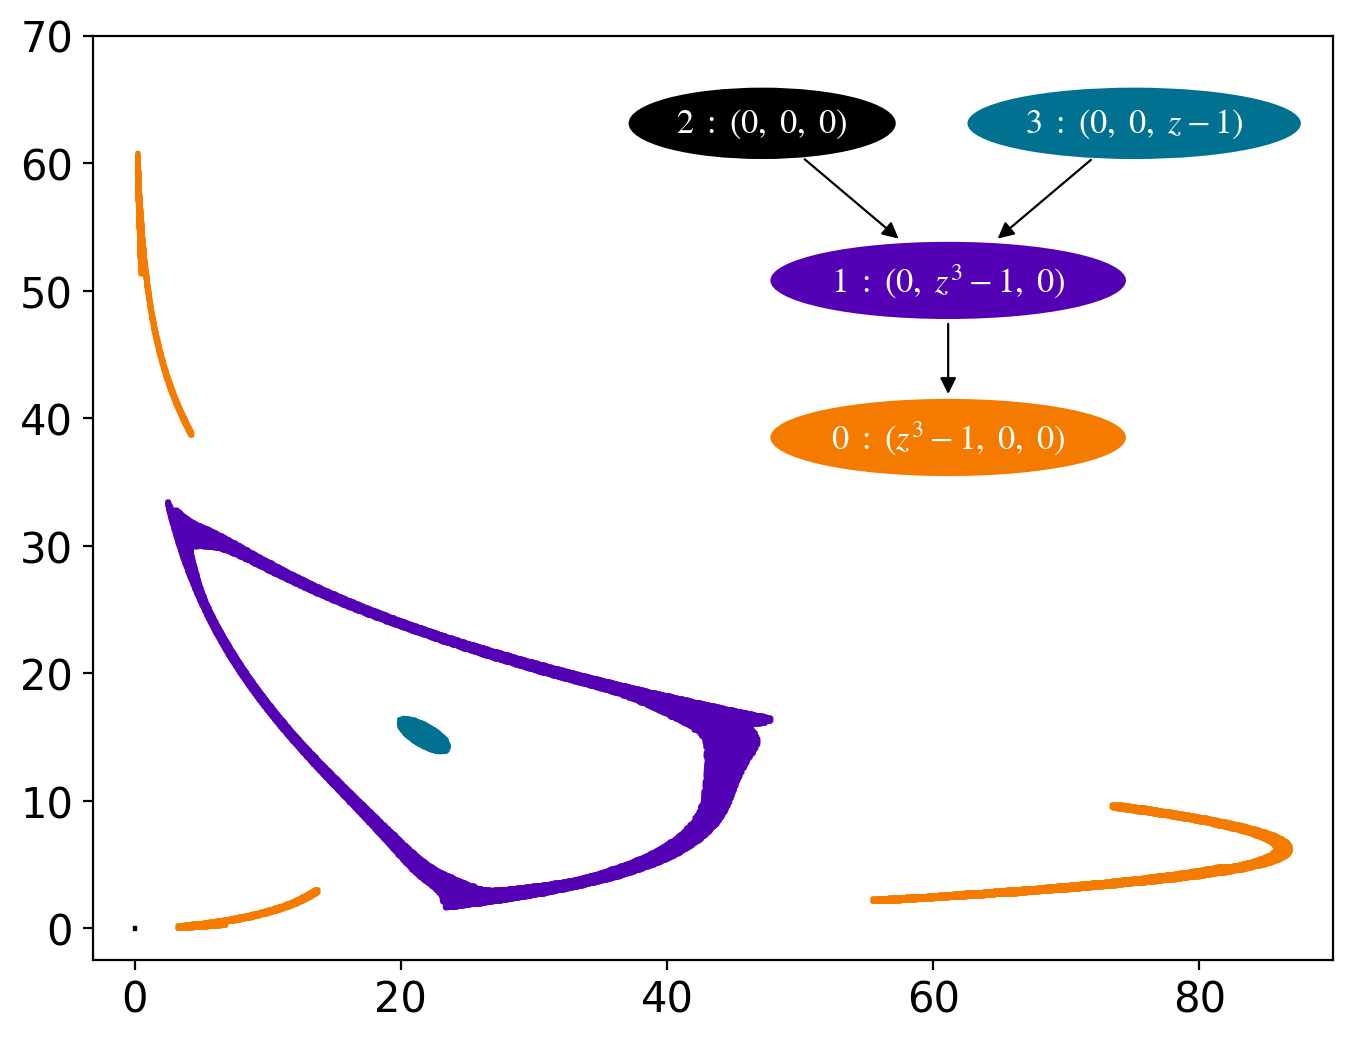

In [16]:
plot_sets(morse_graph, clist, inflation, fname='/content/drive/MyDrive/AMS Colabs/23p45_r23.pdf');

## Computation 4: $\theta_1, \theta_2 \in [23.15, 23.45]$, 23 subdivisions.

In [17]:
theta1 = ("23.15", "23.45")
theta2 = ("23.15", "23.45")
subdiv = 23

th1 = interval(*theta1)
th2 = interval(*theta2)

start = time.time()
model = CMGDB.Model(subdiv, subdiv_max, subdiv, 10000, lower_bounds, upper_bounds, F)
morse_graph, map_graph = CMGDB.ComputeConleyMorseGraph(model)
print(f"Found {morse_graph.num_vertices()} Morse sets in {time.time() - start:.0f} seconds")

clist = ['#f47a00', '#5400b4', '#000000', '#007191']


Found 4 Morse sets in 297 seconds


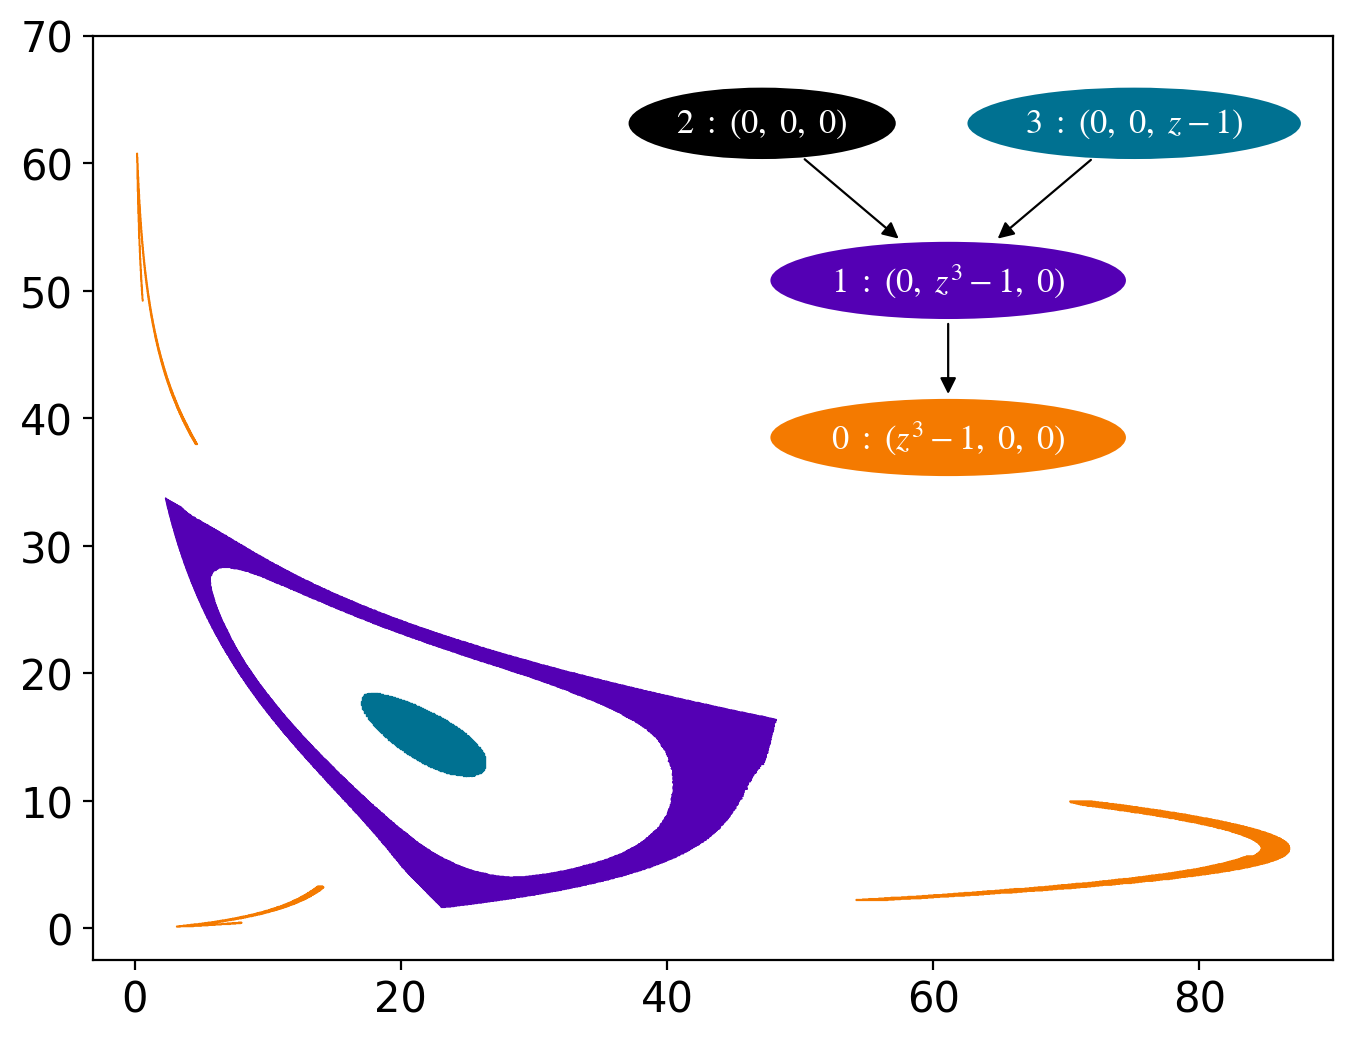

In [18]:
plot_sets(morse_graph, clist);

(<Figure size 800x600 with 1 Axes>, <Axes: >)

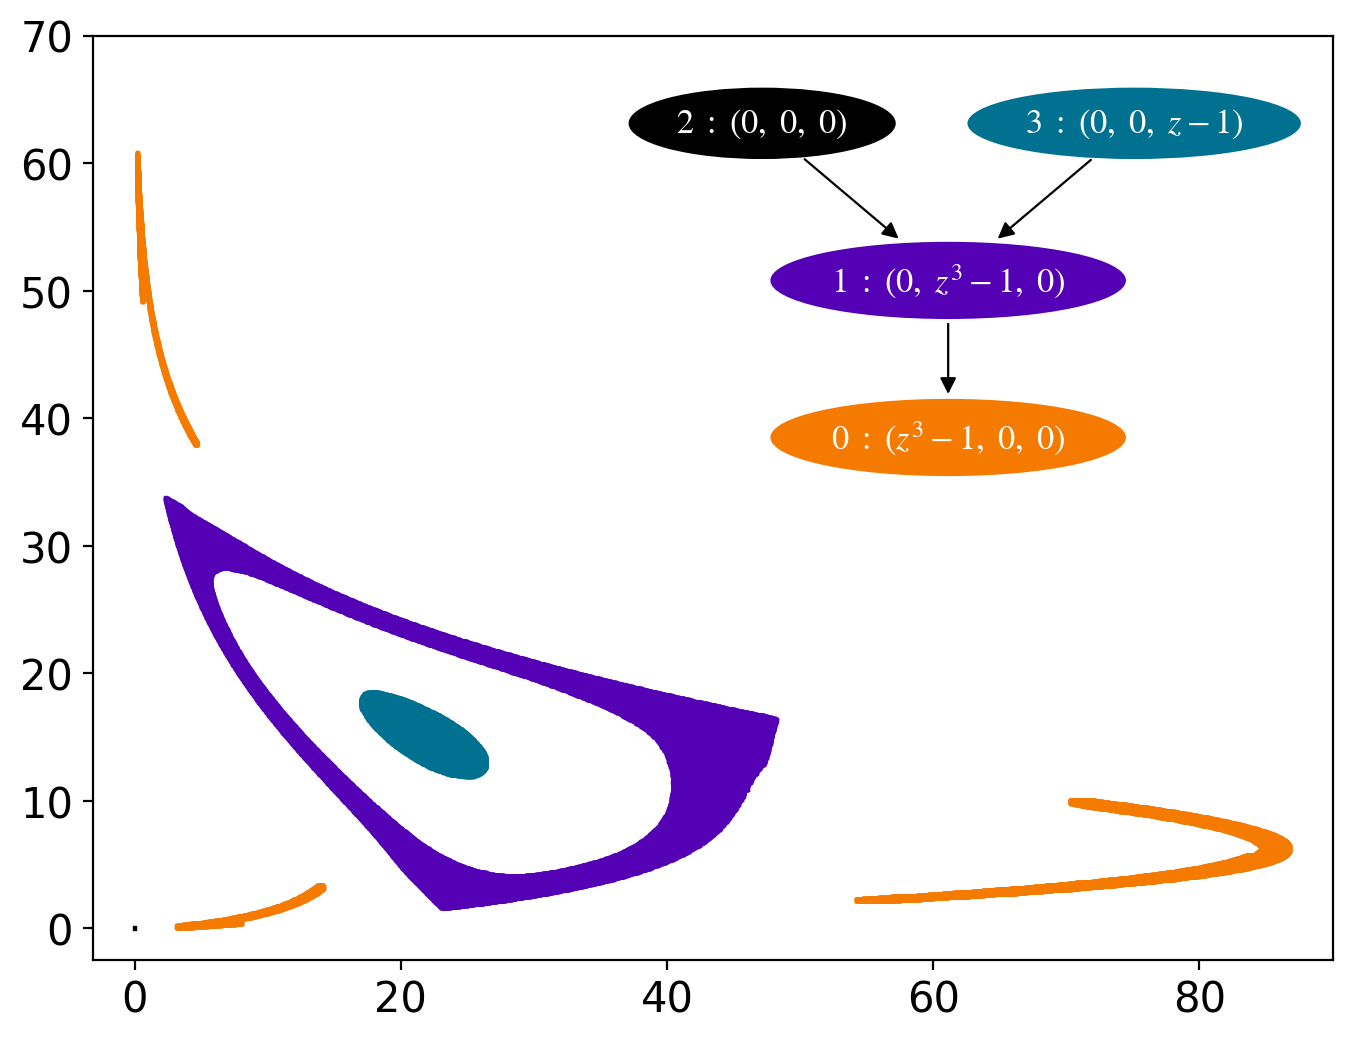

In [19]:
plot_sets(morse_graph, clist, inflation, fname='/content/drive/MyDrive/AMS Colabs/23p15_to_23p45_r23.pdf');

order retraction: all 8040088 components assigned to a Morse set by corollary 2.5 (8040084 outside P), order preserving on every edge -- checked
in 174 seconds


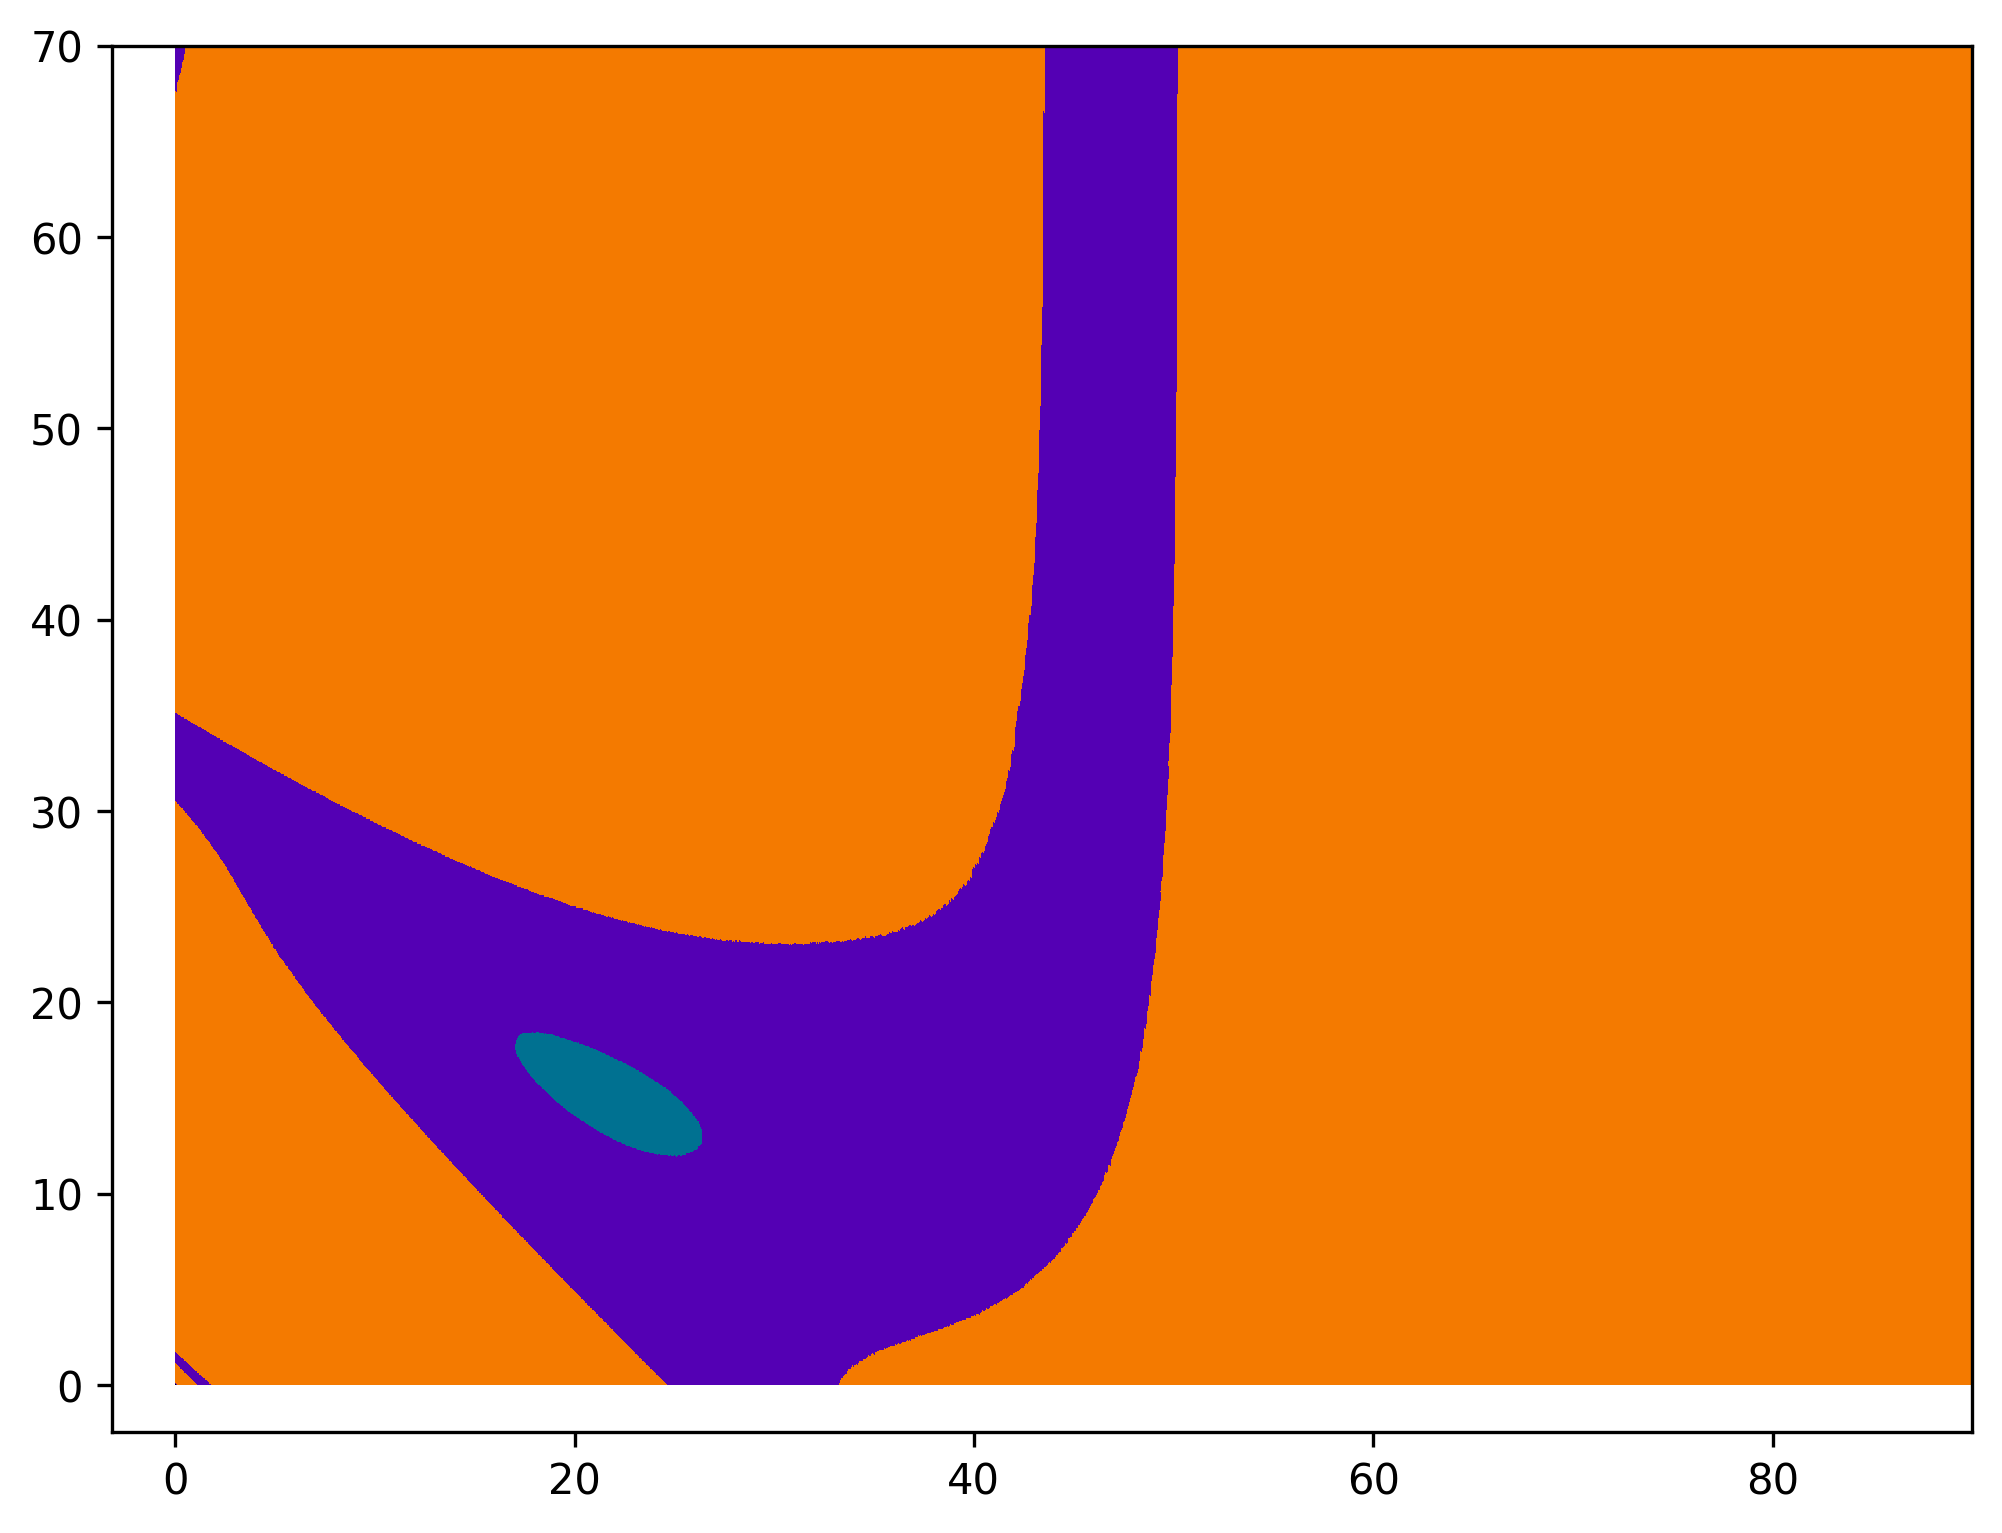

In [22]:
# Order retraction onto the Morse sets: every box of the grid is assigned to one
# Morse set in a way that respects the order, so the grid is partitioned into the
# basins of the Morse decomposition.  Needs cmgdb_retract.py to be importable.
# import cmgdb_retract

start = time.time()
retraction = cmgdb_retract.order_retraction(morse_graph, map_graph)
print(f"{retraction}\nin {time.time() - start:.0f} seconds")

# The box corners, fetched once: there is one call per box and there are millions
# of them, so the second plot below reuses this rather than asking again.
boxes = cmgdb_retract.phase_space_boxes(morse_graph, retraction.sigma.size)

pad = [0.035 * (u - l) for l, u in zip(lower_bounds, upper_bounds)]
basin_bounds = dict(lower_bounds=[l - p for l, p in zip(lower_bounds, pad)],
                    upper_bounds=upper_bounds)

# No Morse graph on this one: the plot is filled edge to edge with the colors of
# the sets, so every node would be drawn on top of its own color.
cmgdb_retract.plot_basins(morse_graph, retraction, clist, boxes=boxes,
                          figsize=(8, 6), **basin_bounds);


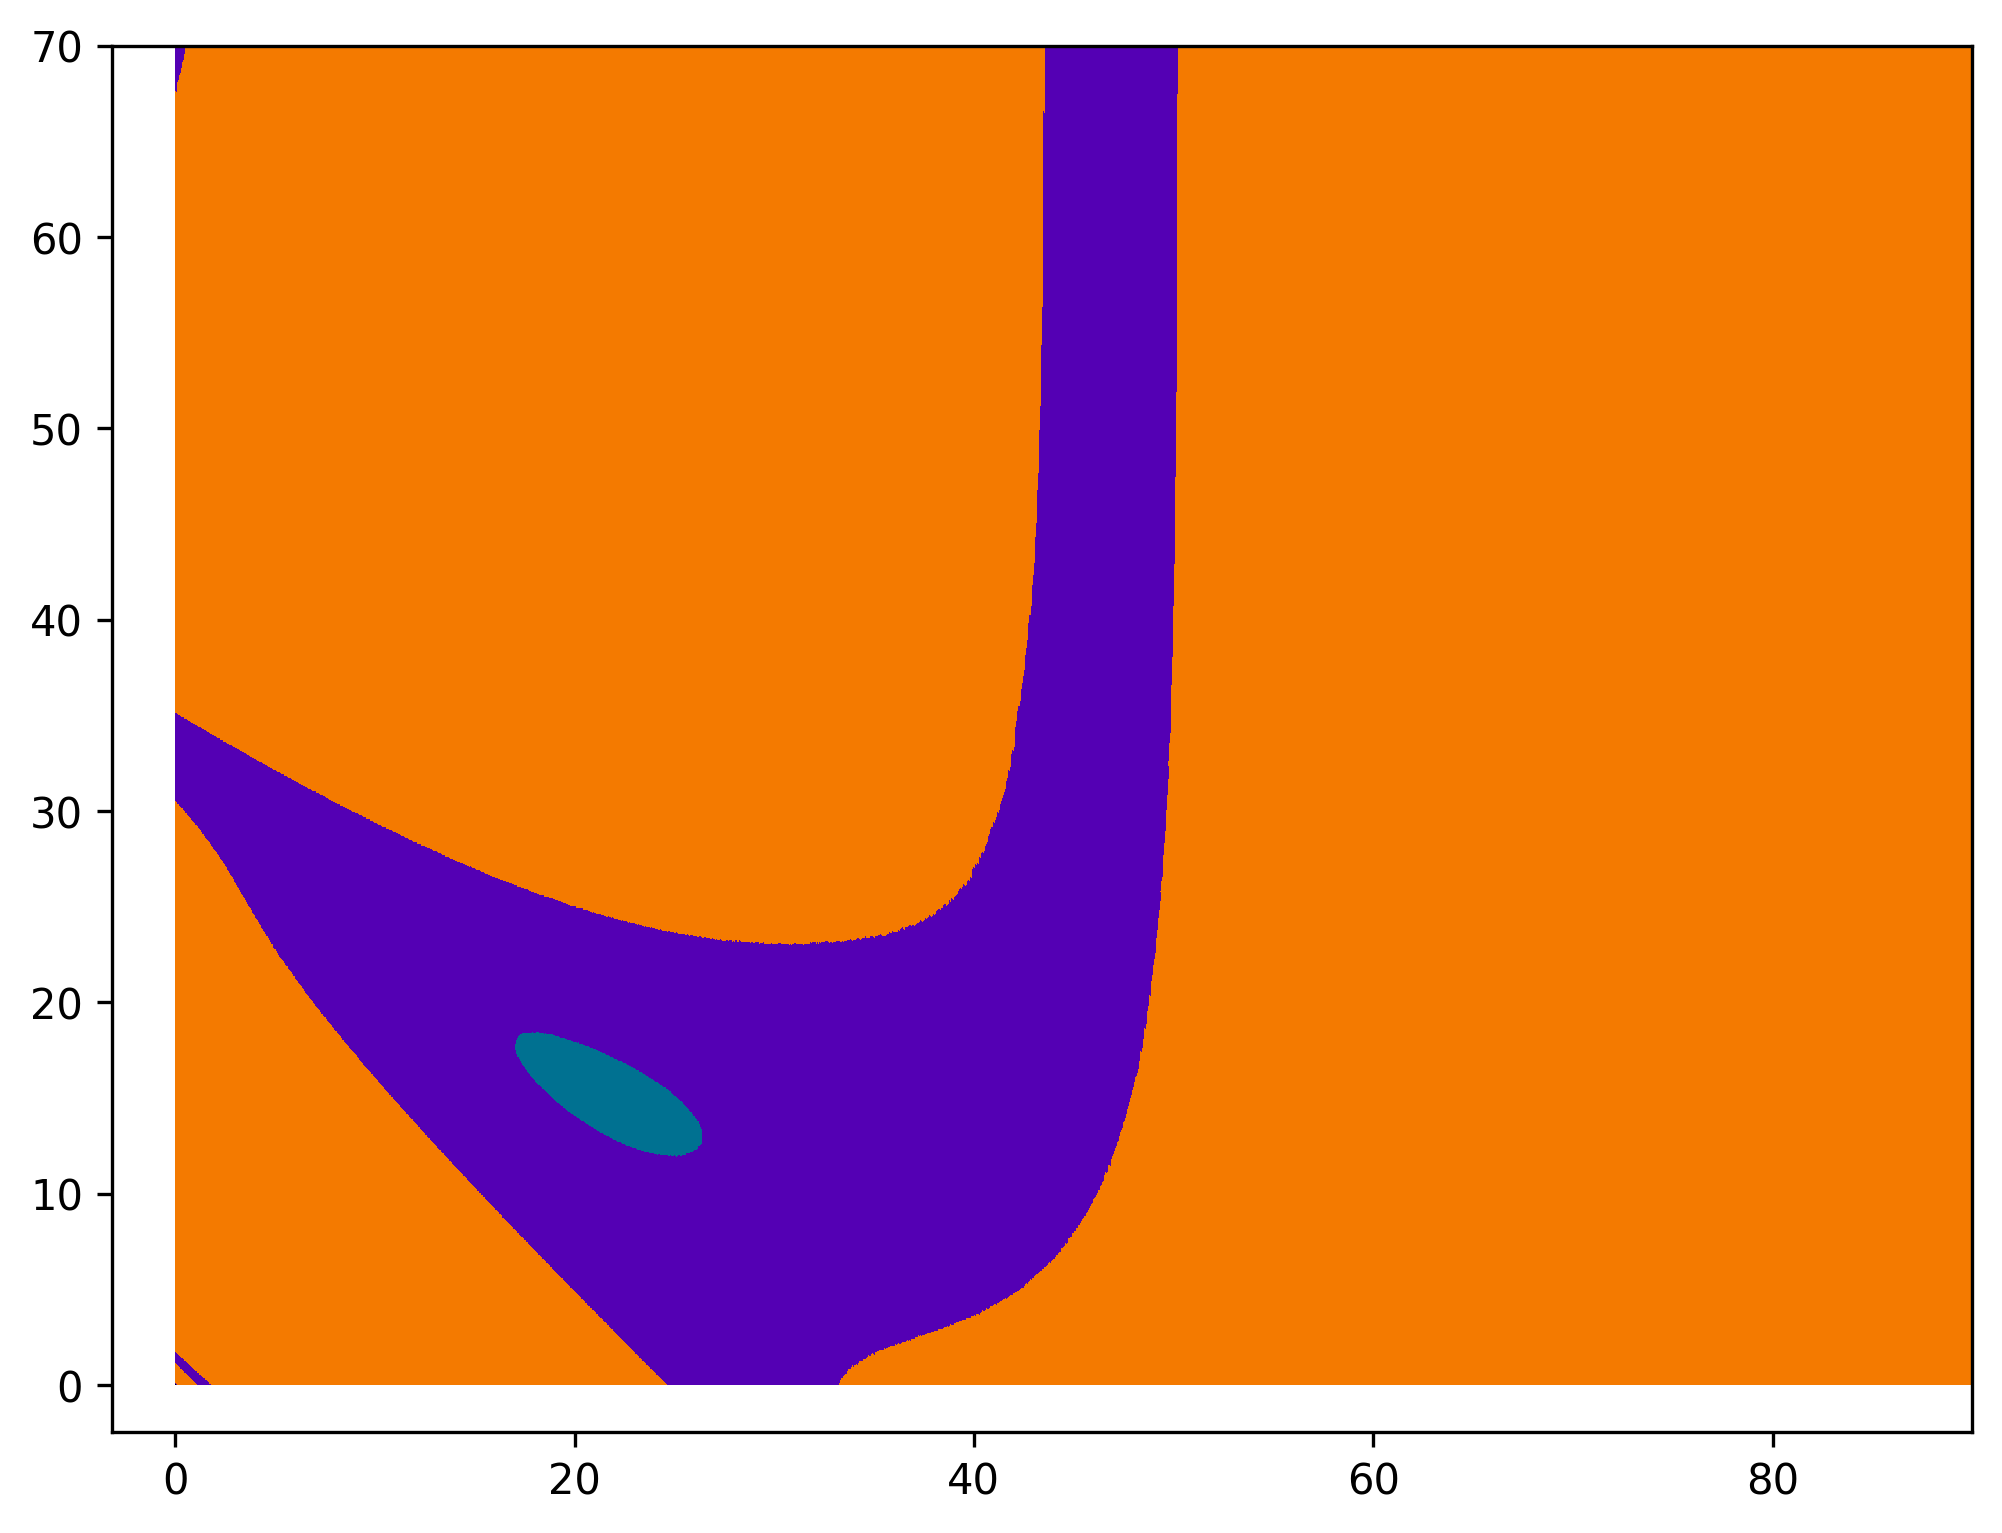

In [25]:
cmgdb_retract.plot_basins(morse_graph, retraction, clist, boxes=boxes,
                          figsize=(8, 6), **basin_bounds,
                          fname='/content/drive/MyDrive/AMS Colabs/23p15_to_23p45_r23_basins.pdf');
